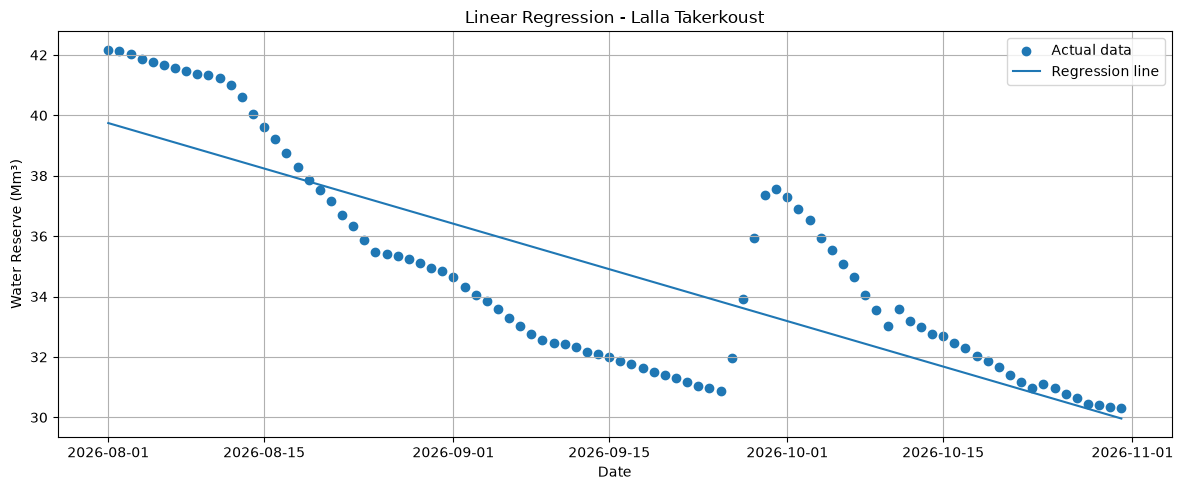

Slope: -0.10750950942465688
Intercept: 39.74495441795232


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

df = pd.read_csv(
    "../data/processed/tensift_cleaned.csv",
    parse_dates=["date"]
)

lalla = df.loc[
    df["dam"] == "Lalla Takerkoust"
].sort_values("date").dropna(subset=["reserve_mm3"])

# X: Number of days since the first observation
x = (lalla["date"] - lalla["date"].min()).dt.days.to_numpy()

# Y: Actual water reserves
y = lalla["reserve_mm3"].to_numpy()

# Fit a linear regression
a, b = np.polyfit(x, y, 1)

# Calculate fitted values
y_pred = a * x + b

# Visualization
plt.figure(figsize=(12, 5))

plt.scatter(lalla["date"], y, label="Actual data")
plt.plot(lalla["date"], y_pred, label="Regression line")

plt.title("Linear Regression - Lalla Takerkoust")
plt.xlabel("Date")
plt.ylabel("Water Reserve (Mm³)")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

print("Slope:", a)
print("Intercept:", b)

Abou El Abess Sebti: slope = -0.0266 Mm³/day
Bge My abdrhmane: slope = -0.0382 Mm³/day
Lalla Takerkoust: slope = -0.1075 Mm³/day
Sd Mohamed Ben Slimane El Jazouli: slope = -0.0153 Mm³/day
Yacoub El Mansour: slope = -0.0836 Mm³/day


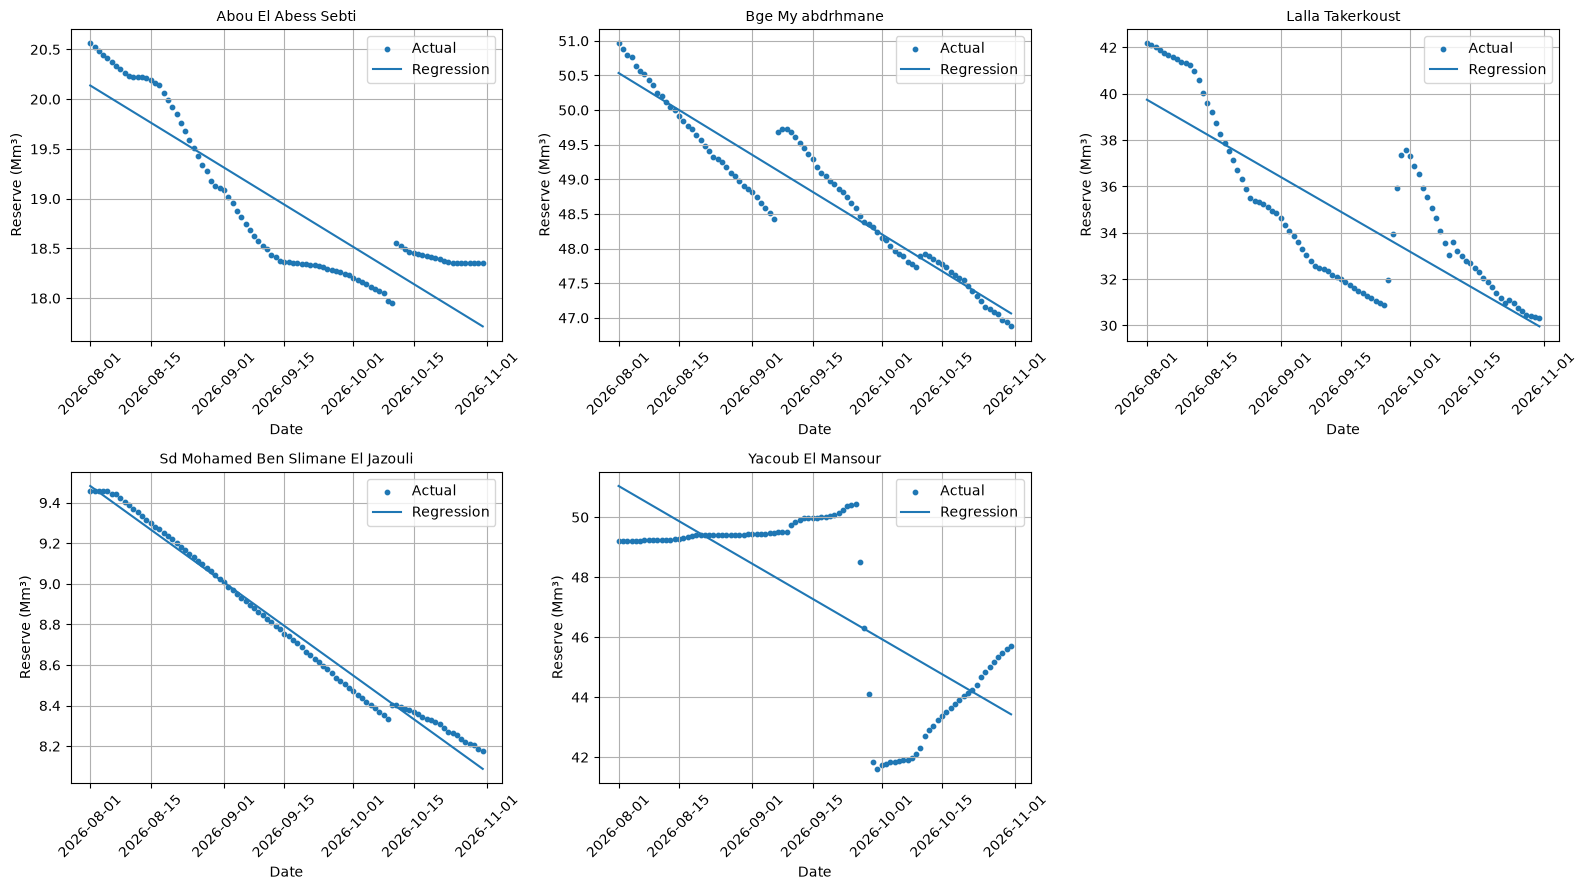

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

df = pd.read_csv(
    "../data/processed/tensift_cleaned.csv",
    parse_dates=["date"]
)

fig, axes = plt.subplots(2, 3, figsize=(16, 9))
axes = axes.flatten()

for i, (dam_name, dam_data) in enumerate(df.groupby("dam")):

    dam_data = dam_data.sort_values("date")
    dam_data = dam_data.dropna(subset=["reserve_mm3"])

    # X: Days since first observation
    x = (
        dam_data["date"] - dam_data["date"].min()
    ).dt.days.to_numpy()

    # Y: Water reserves
    y = dam_data["reserve_mm3"].to_numpy()

    # Linear regression
    a, b = np.polyfit(x, y, 1)

    # Predicted values
    y_pred = a * x + b

    # Actual observations
    axes[i].scatter(
        dam_data["date"], y,
        s=10,
        label="Actual"
    )

    # Regression line
    axes[i].plot(
        dam_data["date"], y_pred,
        label="Regression"
    )

    axes[i].set_title(dam_name, fontsize=10)
    axes[i].set_xlabel("Date")
    axes[i].set_ylabel("Reserve (Mm³)")
    axes[i].tick_params(axis="x", rotation=45)
    axes[i].grid(True)
    axes[i].legend()

    print(f"{dam_name}: slope = {a:.4f} Mm³/day")

# Hide unused sixth plot
axes[5].set_visible(False)

plt.tight_layout()
plt.show()